In [ ]:
# The purpose of this notebook is to find most uncertain formulas and
# inspect the distribution of the candidate predictions uncertainty
# This will be useful in understanding how we should go about which formulas to actually make

In [1]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)


# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
df = df[formula_cols + measured_target_cols].copy()
df[formula_cols] = df[formula_cols].fillna(0.0)
df[measured_target_cols] = df[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(df) == 25, (
    f"Expected the 25 original samples; found {len(df)}."
)
display(df)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


In [2]:
# generate candidate formulas, they are stored in candidate_set

# Formula constraints:
# - TEM: 5-15%.
# - Each chain extender (Joncryl, PEG-DE, NGDE): 0.7-3% when included; 0% when omitted.
# - NC513: 0.7-5%
# - Combined chain extender amount: no more than 6%.
# - Generate 100,000 valid candidate formulas.

import numpy as np
import pandas as pd
candidate_count = 100_000
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(200, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]

    extender_amounts = rng.uniform(
        0.7, 3.0, size=(batch_size, len(chain_extender_cols))
    )
    nc513_idx = chain_extender_cols.index("NC513")
    extender_amounts[:, nc513_idx] = rng.uniform(0.7, 5.0, size=batch_size)

    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 6.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(5.0, 15.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(5.0, 15.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(6.0).all()

for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    upper_bound = 5.0 if col == "NC513" else 3.0
    assert candidate_set.loc[active, col].between(0.7, upper_bound).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 100,000 valid candidate formulas.
         TEM   Joncryl     NC513    PEG-DE      NGDE
0   7.221038  0.000000  0.000000  2.198651  0.000000
1   8.017333  0.850501  1.425145  2.903304  0.000000
2   7.879657  2.472247  0.000000  1.159775  0.000000
3  12.770254  2.128875  0.000000  0.000000  0.791036
4  10.839184  0.000000  2.374614  0.000000  0.000000
Maximum total chain extender: 5.999979539311976


In [4]:
# load the gpr_models
import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")


In [5]:
# Get predictions and standard deviations for these formulas from the GPR models, stored in
# candidate_predictions

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
X_candidates = candidate_set.loc[:, feature_cols]

batch_size = 5_000
prediction_columns = {}

for name, model in gpr_models.items():
    mean_batches = []
    std_batches = []

    for start in range(0, len(X_candidates), batch_size):
        means, stds = model.predict(
            X_candidates.iloc[start : start + batch_size],
            return_std=True,
        )
        mean_batches.append(means)
        std_batches.append(stds)

    prediction_columns[f"pred_{name}"] = np.concatenate(mean_batches)
    prediction_columns[f"std_{name}"] = np.concatenate(std_batches)

predictions = pd.DataFrame(prediction_columns, index=candidate_set.index)
candidate_predictions = pd.concat([candidate_set, predictions], axis=1)

display(candidate_predictions.head())

,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,std_Avg_Density_g_cm3,pred_24h_avg_pct absorption,std_24h_avg_pct absorption,pred_24h_avg_pct_retention,std_24h_avg_pct_retention
0,7.221038,0.000000,0.000000,2.198651,0.000000,0.217058,0.037718,246.161886,27.108971,8.341770,10.477601
1,8.017333,0.850501,1.425145,2.903304,0.000000,0.160348,0.040835,214.281326,26.743534,34.859295,11.473877
2,7.879657,2.472247,0.000000,1.159775,0.000000,0.216838,0.020676,179.705329,28.870202,30.197758,10.928738
3,12.770254,2.128875,0.000000,0.000000,0.791036,0.214557,0.064126,169.243977,91.805925,31.239490,15.401688
4,10.839184,0.000000,2.374614,0.000000,0.000000,0.211257,0.064028,176.498378,56.161615,31.089548,15.357907


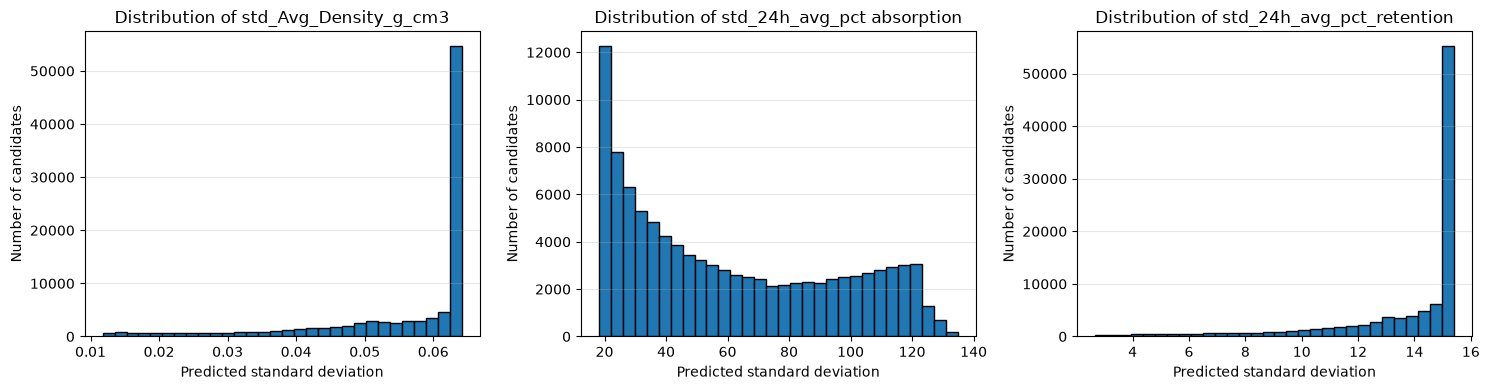

In [6]:
# print the distribution of std for the model predictions for each of the 3 properties

import matplotlib.pyplot as plt

std_cols = [col for col in candidate_predictions.columns if col.startswith("std_")]

fig, axes = plt.subplots(1, len(std_cols), figsize=(5 * len(std_cols), 4))
axes = [axes] if len(std_cols) == 1 else axes

for ax, col in zip(axes, std_cols):
    ax.hist(candidate_predictions[col].dropna(), bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Predicted standard deviation")
    ax.set_ylabel("Number of candidates")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

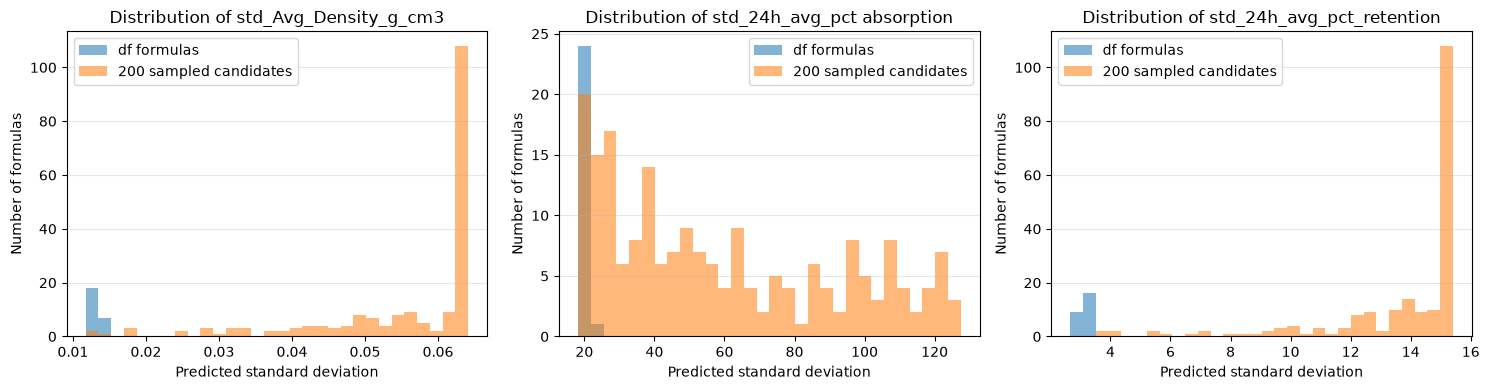

In [8]:
# randomly sample 200 stds from candidate_predictions
# and plot with the std of the 25 training data points to compare

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]

# Prepare formulas from df. Missing TEM rows cannot be predicted.
df_formulas = df.dropna(subset=["TEM"]).copy()
X_df = df_formulas.loc[:, feature_cols].copy()
X_df[chain_extender_cols] = X_df[chain_extender_cols].fillna(0.0)

# Get the model's predicted standard deviation for each formula.
df_std_columns = {}
batch_size = 5_000

for name, model in gpr_models.items():
    std_batches = []

    for start in range(0, len(X_df), batch_size):
        _, stds = model.predict(
            X_df.iloc[start : start + batch_size],
            return_std=True,
        )
        std_batches.append(stds)

    df_std_columns[f"std_{name}"] = np.concatenate(std_batches)

df_predictions = pd.concat(
    [
        df_formulas,
        pd.DataFrame(df_std_columns, index=df_formulas.index),
    ],
    axis=1,
)
# Randomly choose up to 200 candidate formulas (reproducible sample).
candidate_sample = candidate_predictions.sample(
    n=min(200, len(candidate_predictions)),
    random_state=42,
)

# Overlay df and sampled candidate-set standard-deviation distributions.
std_cols = [f"std_{name}" for name in gpr_models]

fig, axes = plt.subplots(1, len(std_cols), figsize=(5 * len(std_cols), 4))
axes = np.atleast_1d(axes)

for ax, col in zip(axes, std_cols):
    df_std = df_predictions[col].dropna().to_numpy()
    candidate_std = candidate_sample[col].dropna().to_numpy()

    combined = np.concatenate([df_std, candidate_std])
    bins = np.histogram_bin_edges(combined, bins=30)

    ax.hist(df_std, bins=bins, alpha=0.55, label="df formulas")
    ax.hist(candidate_std, bins=bins, alpha=0.55, label="200 sampled candidates")

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Predicted standard deviation")
    ax.set_ylabel("Number of formulas")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# print the 15 most uncertain formulas 

std_cols = [f"std_{name}" for name in gpr_models]

most_uncertain = candidate_predictions.copy()
most_uncertain["uncertainty_score"] = (
    most_uncertain[std_cols].rank(pct=True).mean(axis=1) # For each std column separately, it assigns percentile ranks based on that column’s distribution across all formulas. Then it averages each formula’s percentiles across the std columns to get its overall uncertainty score.
)

most_uncertain = most_uncertain.nlargest(15, "uncertainty_score")
display(most_uncertain)

,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,std_Avg_Density_g_cm3,pred_24h_avg_pct absorption,std_24h_avg_pct absorption,pred_24h_avg_pct_retention,std_24h_avg_pct_retention,uncertainty_score
81723,14.984326,2.312945,1.278052,2.329463,0.000000,0.21456,0.064126,208.244709,131.850282,31.248562,15.401931,0.999118
95198,14.982984,1.289218,0.000000,2.774599,1.801093,0.21456,0.064126,212.470625,133.106190,31.248119,15.401931,0.998695
33161,14.995737,1.977930,1.004291,2.230660,0.000000,0.21456,0.064126,215.352047,130.998865,31.248599,15.401931,0.998602
74025,14.995976,1.556673,0.000000,2.795737,0.000000,0.21456,0.064126,213.009253,133.096516,31.248330,15.401931,0.998540
11072,14.998671,1.342379,0.000000,2.412589,1.861044,0.21456,0.064126,216.843765,131.684251,31.248209,15.401931,0.998458
79935,14.982587,2.064263,0.000000,2.109103,1.653142,0.21456,0.064126,209.380381,130.769487,31.248513,15.401931,0.998458
37896,14.982025,2.714978,0.000000,2.688942,0.000000,0.21456,0.064126,196.223096,134.325379,31.248404,15.401931,0.998302
8109,14.989486,0.000000,1.244901,2.941892,0.000000,0.21456,0.064126,233.952177,132.836295,31.246692,15.401931,0.998228
25853,14.973431,2.168000,0.000000,2.965303,0.823469,0.21456,0.064126,198.500817,134.710226,31.248578,15.401931,0.998222
21943,14.967875,1.406386,1.569296,2.855163,0.000000,0.21456,0.064126,214.424714,132.927864,31.248590,15.401931,0.998110


In [11]:
# save the top 100 most uncertain formulas to top_uncertain_formulas.csv in predictions folder

from pathlib import Path

std_cols = [f"std_{name}" for name in gpr_models]
missing_cols = [col for col in std_cols if col not in candidate_predictions.columns]
if missing_cols:
    raise KeyError(f"Missing standard-deviation columns: {missing_cols}")

top_uncertain = candidate_predictions.copy()
top_uncertain["uncertainty_score"] = (
    top_uncertain[std_cols].rank(pct=True).mean(axis=1)
)
top_uncertain = top_uncertain.nlargest(100, "uncertainty_score")

project_root = (
    Path.cwd().resolve().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd().resolve()
)
predictions_dir = project_root / "predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

output_path = predictions_dir / "top_uncertain_formulas.csv"
top_uncertain.to_csv(output_path, index=False)

print(f"Saved {len(top_uncertain)} formulas to: {output_path}")

Saved 100 formulas to: C:\Users\Brooke\Foam project\predictions\top_uncertain_formulas.csv
